# Pathrise Fellow Placement Prediction

## Project Overview
This notebook explores the Pathrise fellow dataset and develops classification models to predict whether a fellow is placed. It documents the full workflow—from data inspection and preprocessing through model comparison—and includes a supplementary regression exercise.

**Objective:** predict the `placed` outcome from the available fellow, cohort, and job-search information.

**Dataset:** a fellow-level dataset loaded from `Data_Pathrise.xlsx`. It contains placement outcomes, job-search activity, demographic and educational attributes, program status, and cohort information.

**Workflow roadmap**
1. Environment setup and data loading
2. Exploratory data analysis and visualization
3. Outlier review and management
4. Feature engineering and transformation
5. Missing-value handling
6. Categorical encoding and data export
7. Classification modeling and hyperparameter search
8. Model evaluation and serialization
9. Supplementary regression analysis

> The notebook narrative describes the operations implemented in the cells below. In particular, the train/test split does not pass a `stratify` argument, and several preprocessing choices are fixed values rather than values computed from the training split.

## Phase 1: Environment Setup & Data Loading

The notebook imports the analysis and visualization libraries, then loads the Pathrise workbook into a pandas DataFrame. Initial previews and schema checks establish the working dataset and confirm its columns and types.


In [1]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib import style

## Phase 2: Exploratory Data Analysis (EDA) & Visualization

This phase summarizes the dataset’s structure, distributions, missingness, and relationship to placement. Summary statistics and visualizations help identify candidate predictors, class balance, and data-quality issues before preprocessing. The plots and counts below focus on education, demographic attributes, job-search activity, and placement status.

### Load the Source Dataset

Read the Excel source into `df`; the subsequent cells preview the records and inspect the dataset’s schema and summary statistics.


In [2]:
df=pd.read_excel('Data_Pathrise.xlsx')

In [3]:
df.head()

,id,pathrise_status,primary_track,cohort_tag,program_duration_days,placed,employment_status,highest_level_of_education,length_of_job_search,biggest_challenge_in_search,professional_experience,work_authorization_status,number_of_interviews,number_of_applications,gender,race
0,1,Active,SWE,OCT19A,NaN,0,Unemployed,Bachelor's Degree,3-5 months,Hearing back on my applications,3-4 years,Canada Citizen,2.0,900,Male,Non-Hispanic White or Euro-American
1,2,Active,PSO,JAN20A,NaN,0,Unemployed,"Some College, No Degree",3-5 months,Getting past final round interviews,1-2 years,Citizen,6.0,0,Male,Non-Hispanic White or Euro-American
2,3,Closed Lost,Design,AUG19B,0.0,0,Employed Part-Time,Master's Degree,Less than one month,Figuring out which jobs to apply for,Less than one year,Citizen,0.0,0,Male,East Asian or Asian American
3,4,Closed Lost,PSO,AUG19B,0.0,0,Contractor,Bachelor's Degree,Less than one month,Getting past final round interviews,Less than one year,Citizen,5.0,25,Male,Decline to Self Identify
4,5,Placed,SWE,AUG19A,89.0,1,Unemployed,Bachelor's Degree,1-2 months,Hearing back on my applications,1-2 years,F1 Visa/OPT,10.0,100,Male,East Asian or Asian American


In [4]:
df[df['placed']==1]['number_of_interviews'].value_counts()

number_of_interviews
0.0     302
1.0     178
2.0     123
4.0      73
3.0      68
5.0      52
6.0      31
7.0      22
10.0      9
20.0      5
11.0      4
8.0       3
19.0      2
15.0      1
12.0      1
14.0      1
16.0      1
17.0      1
Name: count, dtype: int64

In [5]:
df[df['placed']==1]['number_of_applications'].value_counts()

number_of_applications
15     113
10      63
30      62
20      61
25      60
50      42
35      40
70      39
40      38
6       35
45      34
8       32
60      30
3       29
7       28
0       27
2       25
1       25
4       23
80      22
9       21
5       20
90      19
100     10
130      9
200      7
150      7
140      6
110      6
190      5
160      5
170      5
120      4
400      2
180      2
Name: count, dtype: int64

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2544 entries, 0 to 2543
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           2544 non-null   int64  
 1   pathrise_status              2544 non-null   object 
 2   primary_track                2544 non-null   object 
 3   cohort_tag                   2536 non-null   object 
 4   program_duration_days        1928 non-null   float64
 5   placed                       2544 non-null   int64  
 6   employment_status            2315 non-null   object 
 7   highest_level_of_education   2486 non-null   object 
 8   length_of_job_search         2470 non-null   object 
 9   biggest_challenge_in_search  2520 non-null   object 
 10  professional_experience      2322 non-null   object 
 11  work_authorization_status    2260 non-null   object 
 12  number_of_interviews         2326 non-null   float64
 13  number_of_applicat

In [7]:
df.describe()

,id,program_duration_days,placed,number_of_interviews,number_of_applications
count,2544.000000,1928.000000,2544.000000,2326.000000,2544.000000
mean,1272.500000,136.098548,0.375786,2.182287,36.500786
std,734.533866,125.860248,0.484420,2.959273,53.654896
min,1.000000,0.000000,0.000000,0.000000,0.000000
25%,636.750000,14.000000,0.000000,0.000000,9.000000
50%,1272.500000,112.000000,0.000000,1.000000,20.000000
75%,1908.250000,224.000000,1.000000,3.000000,45.000000
max,2544.000000,548.000000,1.000000,20.000000,1000.000000


In [8]:
df.isnull().sum().sort_values(ascending=False)

program_duration_days          616
gender                         492
work_authorization_status      284
employment_status              229
professional_experience        222
number_of_interviews           218
length_of_job_search            74
highest_level_of_education      58
biggest_challenge_in_search     24
race                            18
cohort_tag                       8
id                               0
pathrise_status                  0
primary_track                    0
placed                           0
number_of_applications           0
dtype: int64

([0, 1, 2, 3, 4, 5, 6],
 [Text(0, 0, "Bachelor's Degree"),
  Text(1, 0, 'Some College, No Degree'),
  Text(2, 0, "Master's Degree"),
  Text(3, 0, 'Doctorate or Professional Degree'),
  Text(4, 0, 'High School Graduate'),
  Text(5, 0, 'GED or equivalent'),
  Text(6, 0, 'Some High School')])

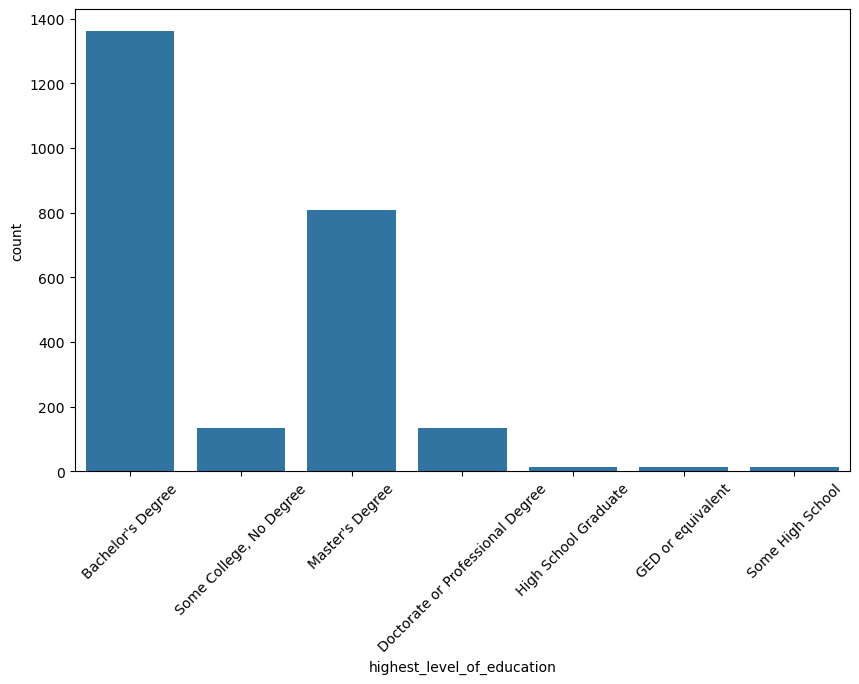

In [9]:
plt.figure(figsize=(10,6))
sns.countplot(x="highest_level_of_education",data=df)
plt.xticks(rotation=45)

In [10]:
df[df['highest_level_of_education']=='High School Graduate']['placed'].value_counts()

placed
1    10
0     5
Name: count, dtype: int64

In [11]:
df[df['highest_level_of_education']=='GED or equivalent']['placed'].value_counts()

placed
0    10
1     5
Name: count, dtype: int64

In [12]:
df[df['highest_level_of_education']=='Some High School']['placed'].value_counts()

placed
0    11
1     4
Name: count, dtype: int64

In [13]:
df[df['highest_level_of_education'].isna()]['placed'].value_counts()

placed
0    42
1    16
Name: count, dtype: int64

([0, 1, 2, 3, 4, 5, 6, 7, 8],
 [Text(0, 0, 'Non-Hispanic White or Euro-American'),
  Text(1, 0, 'East Asian or Asian American'),
  Text(2, 0, 'Decline to Self Identify'),
  Text(3, 0, 'Black, Afro-Caribbean, or African American'),
  Text(4, 0, 'Latino or Hispanic American'),
  Text(5, 0, 'Middle Eastern or Arab American'),
  Text(6, 0, 'South Asian or Indian American'),
  Text(7, 0, 'Two or More Races'),
  Text(8, 0, 'Native American or Alaskan Native')])

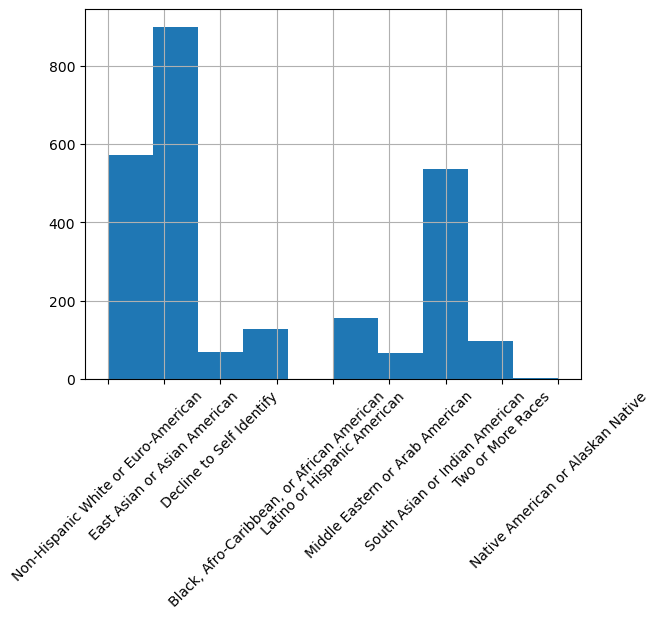

In [14]:
df["race"].hist()
plt.xticks(rotation=45)

([0, 1, 2, 3, 4, 5, 6, 7, 8],
 [Text(0, 0, 'Non-Hispanic White or Euro-American'),
  Text(1, 0, 'East Asian or Asian American'),
  Text(2, 0, 'Decline to Self Identify'),
  Text(3, 0, 'Black, Afro-Caribbean, or African American'),
  Text(4, 0, 'Latino or Hispanic American'),
  Text(5, 0, 'Middle Eastern or Arab American'),
  Text(6, 0, 'South Asian or Indian American'),
  Text(7, 0, 'Two or More Races'),
  Text(8, 0, 'Native American or Alaskan Native')])

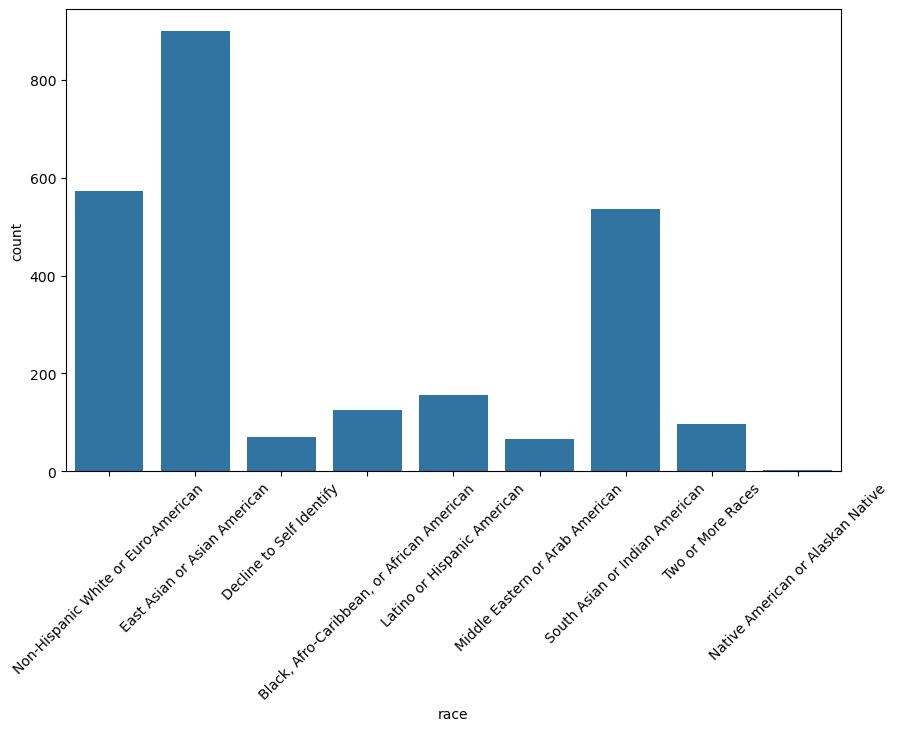

In [15]:
plt.figure(figsize=(10,6))
sns.countplot(x="race",data=df)
plt.xticks(rotation=45)

In [16]:
df_filter=df[df["pathrise_status"]!="Active"]

In [17]:
df_filter.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2012 entries, 2 to 2543
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           2012 non-null   int64  
 1   pathrise_status              2012 non-null   object 
 2   primary_track                2012 non-null   object 
 3   cohort_tag                   2006 non-null   object 
 4   program_duration_days        1928 non-null   float64
 5   placed                       2012 non-null   int64  
 6   employment_status            1824 non-null   object 
 7   highest_level_of_education   1968 non-null   object 
 8   length_of_job_search         1943 non-null   object 
 9   biggest_challenge_in_search  1992 non-null   object 
 10  professional_experience      1846 non-null   object 
 11  work_authorization_status    1781 non-null   object 
 12  number_of_interviews         1831 non-null   float64
 13  number_of_applications 

In [18]:
df_dropmiss= df_filter.dropna(axis=0)
df_dropmiss.info()

<class 'pandas.core.frame.DataFrame'>
Index: 988 entries, 2 to 2543
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           988 non-null    int64  
 1   pathrise_status              988 non-null    object 
 2   primary_track                988 non-null    object 
 3   cohort_tag                   988 non-null    object 
 4   program_duration_days        988 non-null    float64
 5   placed                       988 non-null    int64  
 6   employment_status            988 non-null    object 
 7   highest_level_of_education   988 non-null    object 
 8   length_of_job_search         988 non-null    object 
 9   biggest_challenge_in_search  988 non-null    object 
 10  professional_experience      988 non-null    object 
 11  work_authorization_status    988 non-null    object 
 12  number_of_interviews         988 non-null    float64
 13  number_of_applications  

In [19]:
for column in df.columns:
    print(df[column].value_counts())
    print("-------------------------")

id
1       1
1700    1
1693    1
1694    1
1695    1
       ..
849     1
850     1
851     1
852     1
2544    1
Name: count, Length: 2544, dtype: int64
-------------------------
pathrise_status
Placed                956
Active                532
Withdrawn             398
Withdrawn (Trial)     276
Closed Lost           182
Withdrawn (Failed)     82
MIA                    52
Deferred               34
Break                  32
Name: count, dtype: int64
-------------------------
primary_track
SWE          1678
PSO           322
Design        288
Data          248
Web             6
Marketing       2
Name: count, dtype: int64
-------------------------
cohort_tag
JAN19A    132
JAN20A    124
DEC18A    116
FEB20A    108
AUG19C     88
OCT18B     84
OCT18A     82
AUG19B     82
JAN20B     82
JAN19B     74
MAR19A     74
OCT19A     68
SEP19B     66
JUL19A     66
JUN19B     64
DEC19A     64
FEB19A     64
NOV18A     62
NOV19A     62
SEP19A     60
AUG19A     60
OCT19B     54
SEP18C     54
JUN19A     5

In [20]:
for column in df.columns:
    print(column)
    print(df[column].isnull().sum())
    print("-------------------------")

id
0
-------------------------
pathrise_status
0
-------------------------
primary_track
0
-------------------------
cohort_tag
8
-------------------------
program_duration_days
616
-------------------------
placed
0
-------------------------
employment_status 
229
-------------------------
highest_level_of_education
58
-------------------------
length_of_job_search
74
-------------------------
biggest_challenge_in_search
24
-------------------------
professional_experience
222
-------------------------
work_authorization_status
284
-------------------------
number_of_interviews
218
-------------------------
number_of_applications
0
-------------------------
gender
492
-------------------------
race
18
-------------------------


In [21]:
for column in df_filter.columns:
    print(column)
    print(df_filter[column].isnull().sum())
    print("-------------------------")

id
0
-------------------------
pathrise_status
0
-------------------------
primary_track
0
-------------------------
cohort_tag
6
-------------------------
program_duration_days
84
-------------------------
placed
0
-------------------------
employment_status 
188
-------------------------
highest_level_of_education
44
-------------------------
length_of_job_search
69
-------------------------
biggest_challenge_in_search
20
-------------------------
professional_experience
166
-------------------------
work_authorization_status
231
-------------------------
number_of_interviews
181
-------------------------
number_of_applications
0
-------------------------
gender
388
-------------------------
race
13
-------------------------


In [22]:
covariance = df["number_of_interviews"].cov(df["placed"])
covariance

np.float64(-0.01026488780406624)

In [23]:
for column in df_filter.columns:
    column_type = df[column].dtype
    if column_type==object:
       pass
    else:
        print(column)
        print(df[column].cov(df["placed"]))
        print("-------------------------")

id
-12.593000393236338
-------------------------
program_duration_days
12.414005387515694
-------------------------
placed
0.23466316463741876
-------------------------
number_of_interviews
-0.01026488780406624
-------------------------
number_of_applications
-0.7372204374074104
-------------------------


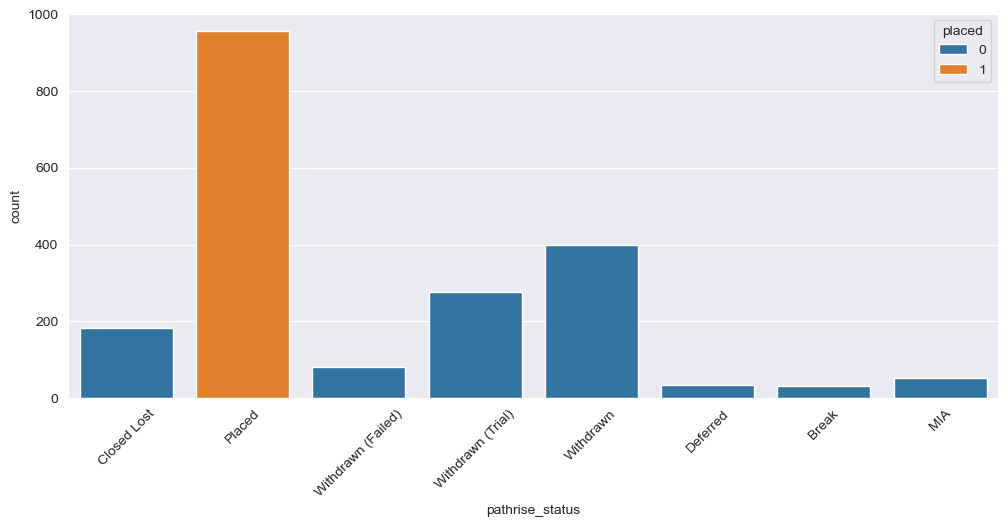

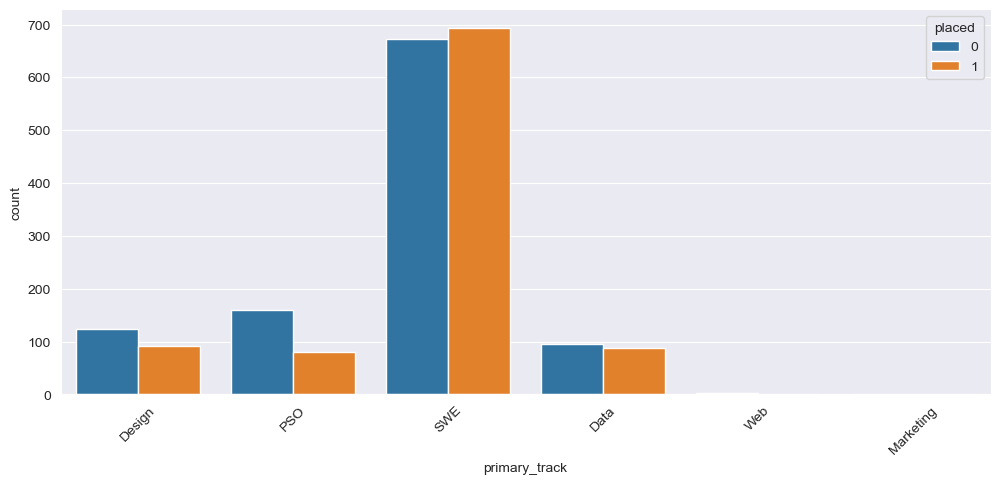

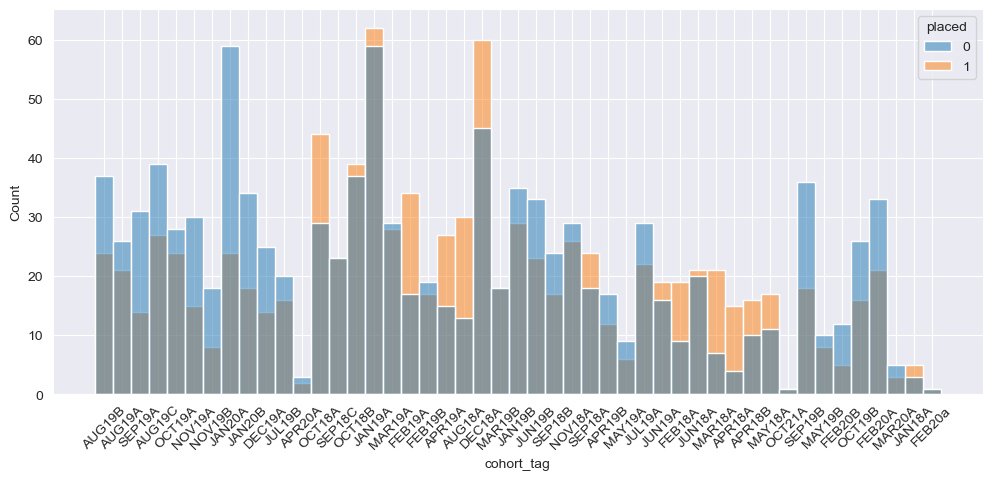

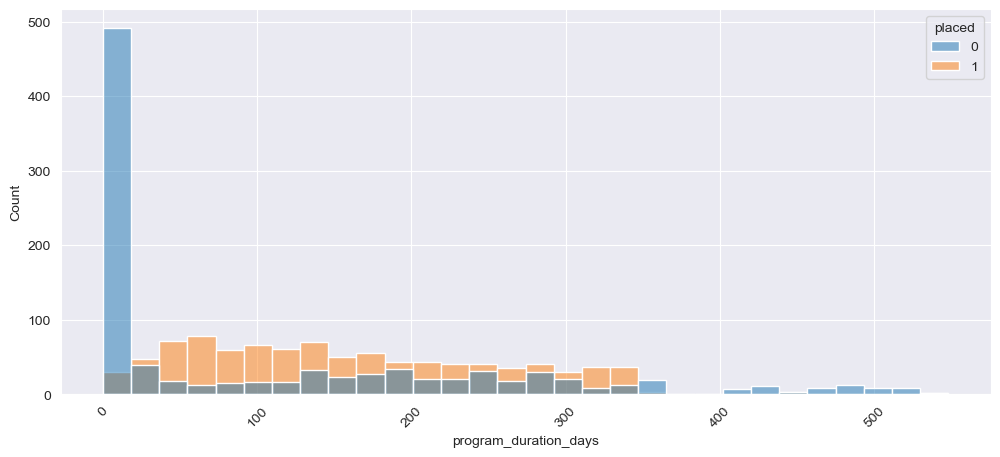

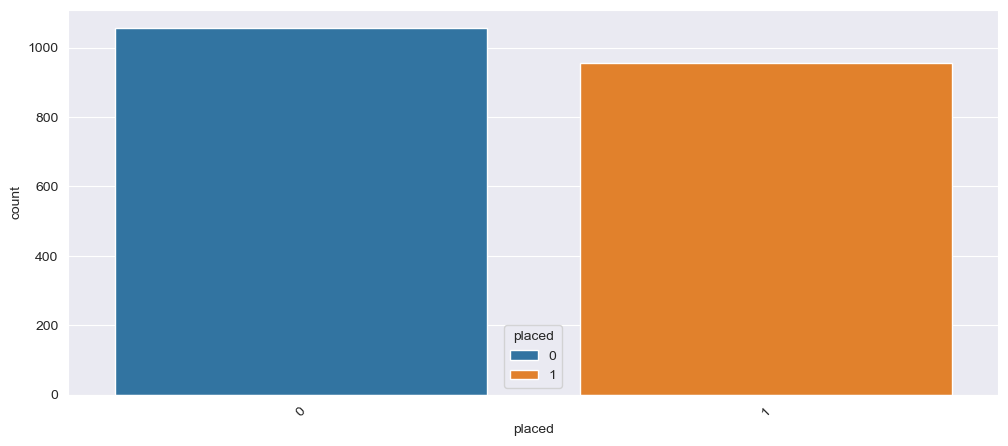

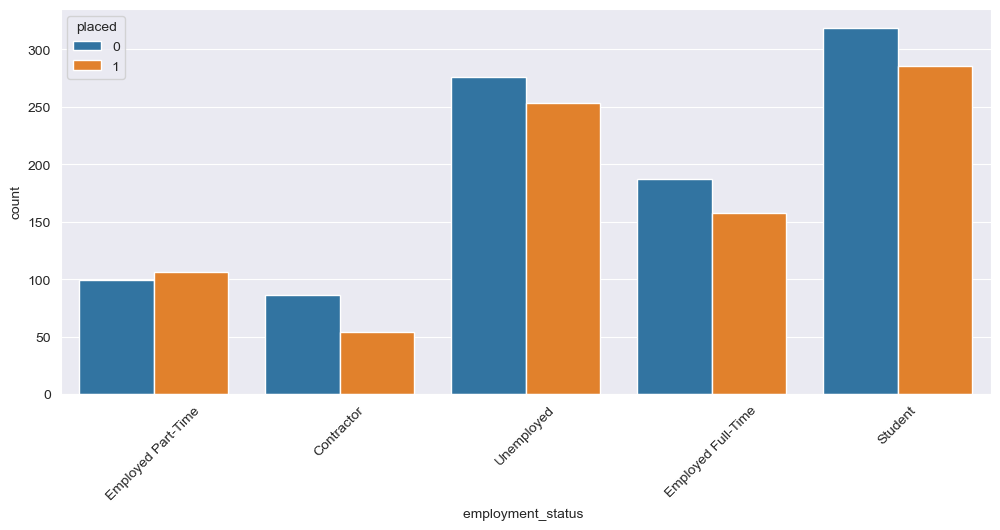

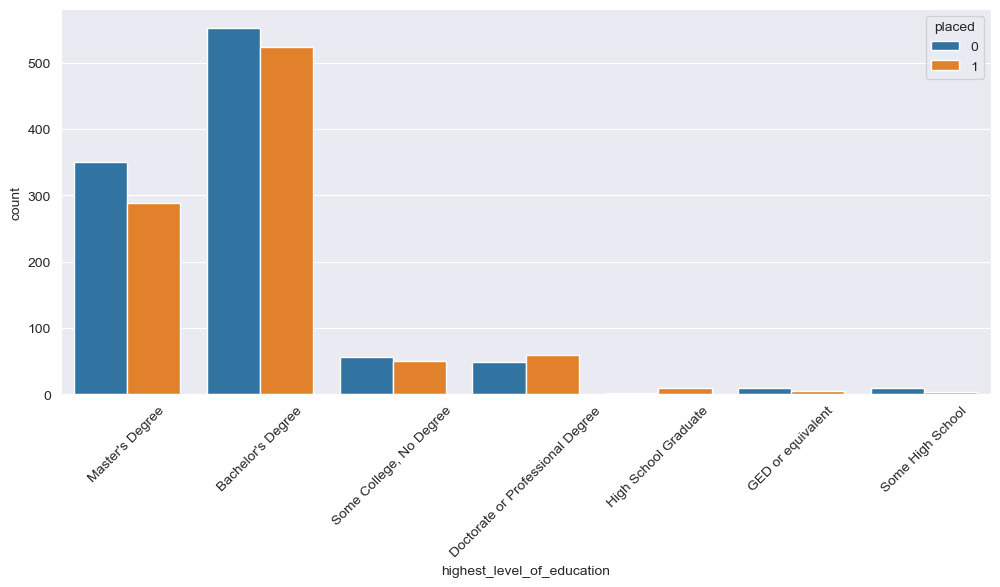

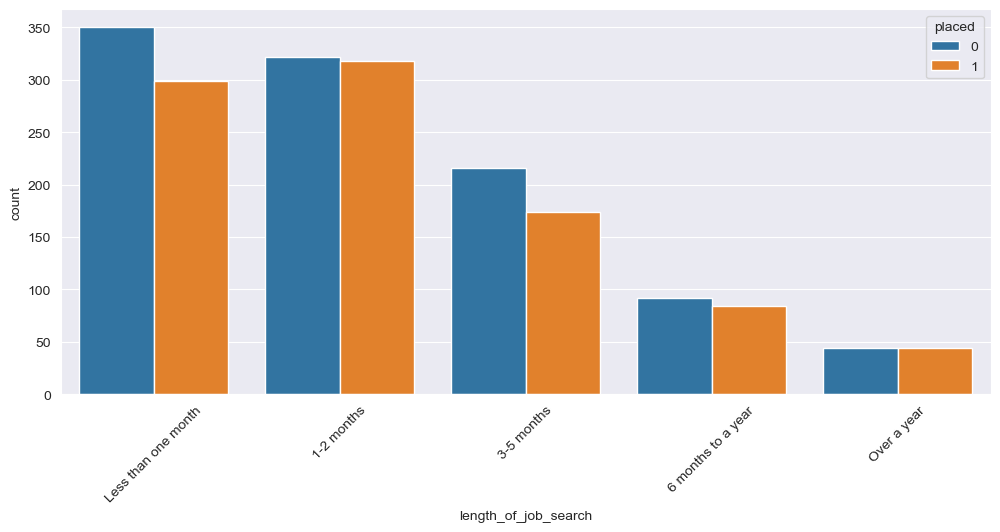

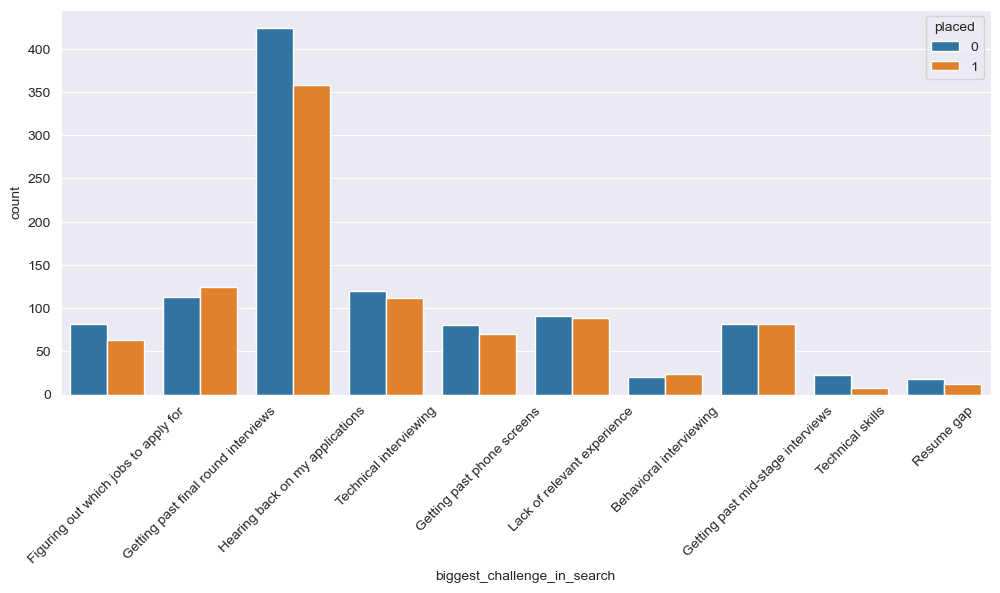

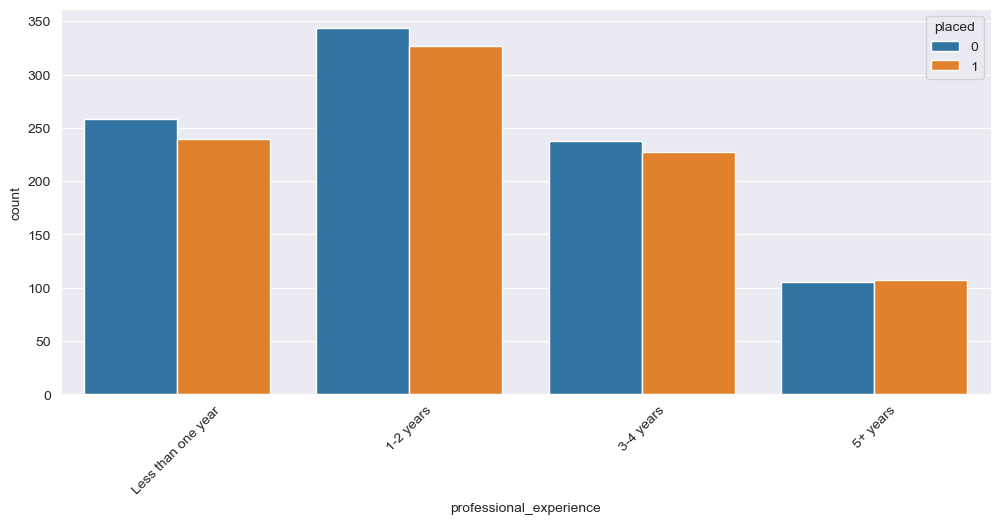

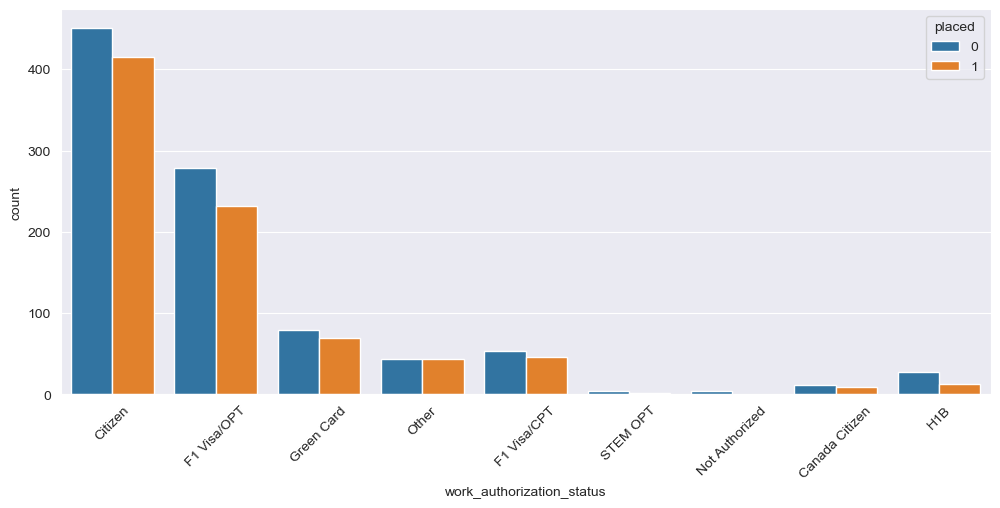

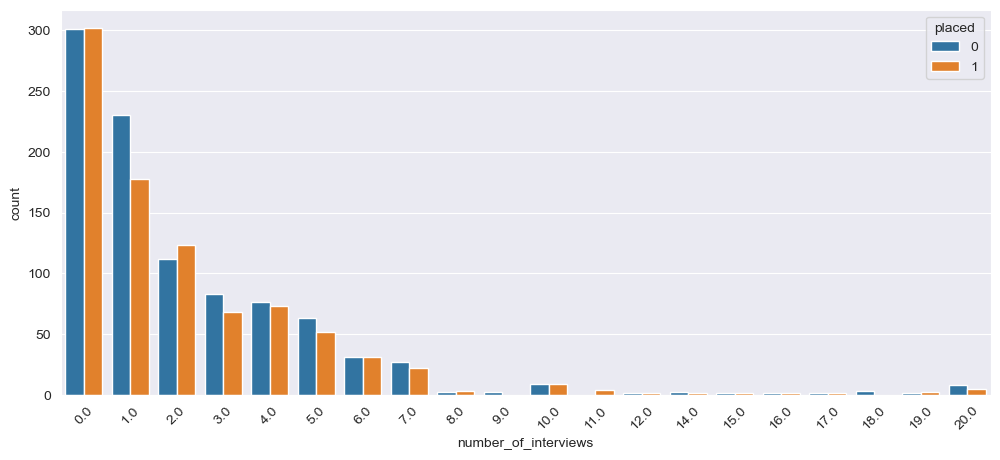

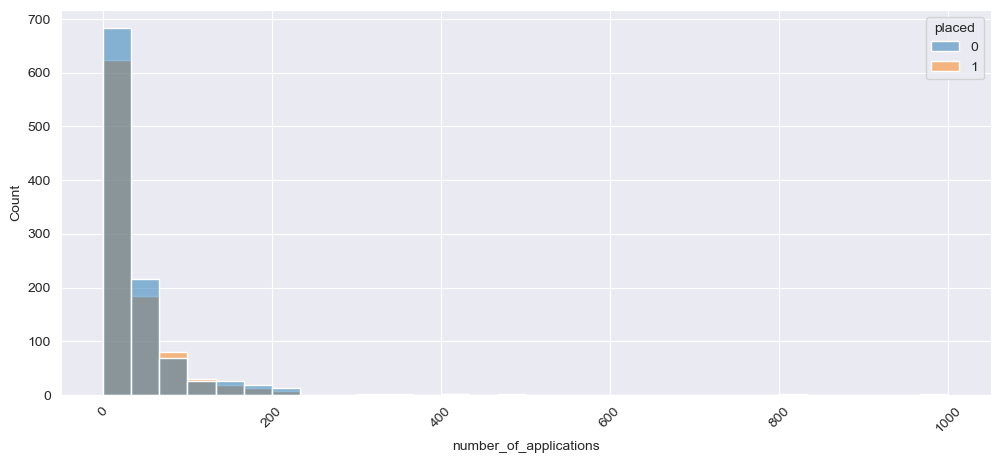

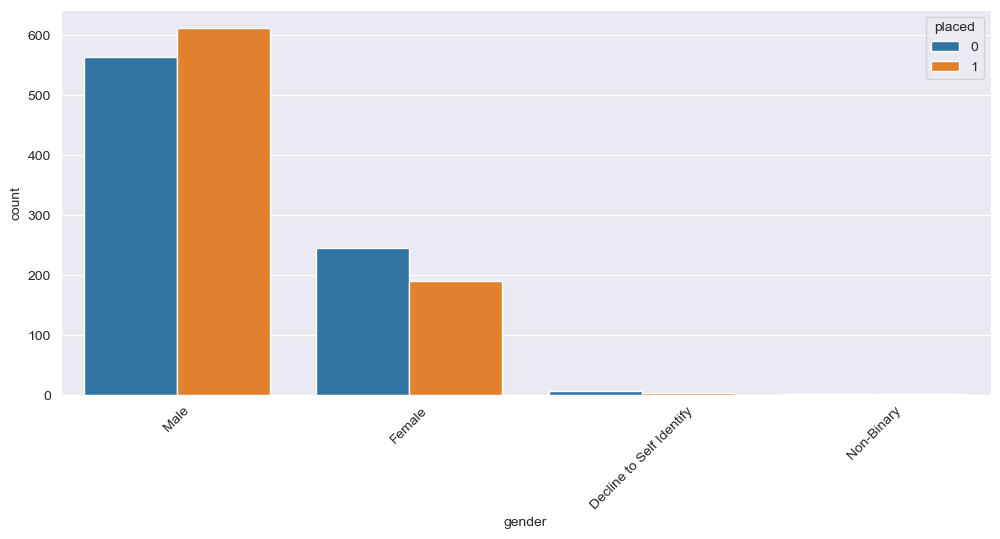

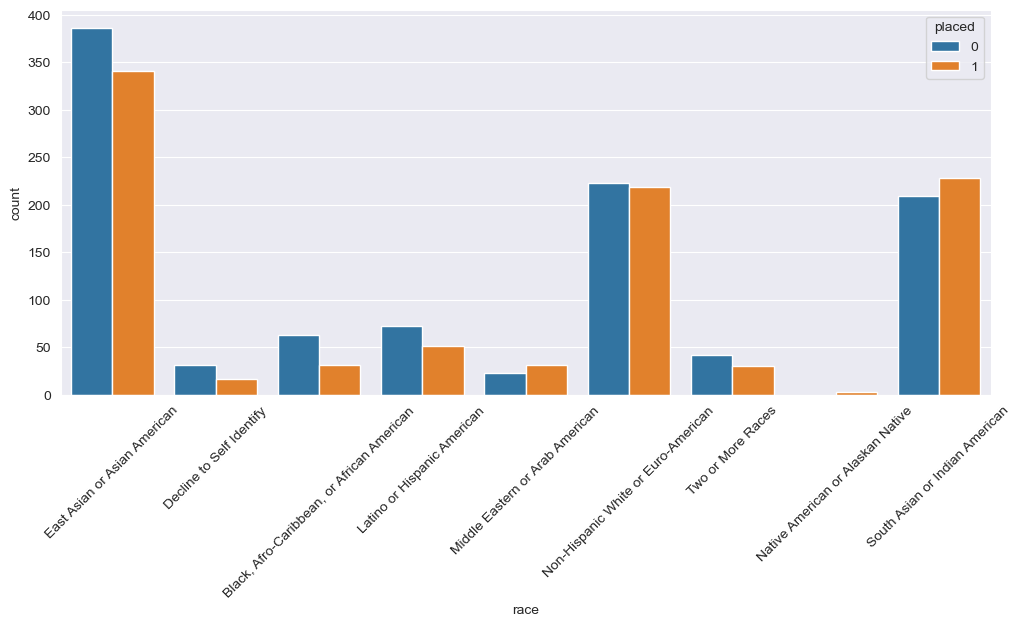

In [24]:
for column in df_filter.columns:
    if column == 'id':
        continue
    plt.figure(figsize=(12, 5))
    sns.set_style('darkgrid')
    if df_filter[column].nunique() > 20:
        sns.histplot(data=df_filter, x=column, hue='placed', bins=30)
    else:
        sns.countplot(x=column, data=df_filter, hue='placed')
    plt.xticks(rotation=45)
    plt.show()

## Phase 3: Data Preprocessing & Outlier Management

This phase reviews numeric features and reduces the influence of unusually high application counts before downstream analysis. The notebook’s filtering step is applied to `number_of_applications`; the subsequent cells continue using the filtered dataframe.

### IQR-Based Outlier Review

The interquartile range (IQR) is calculated as an upper quartile minus a lower quartile. Values above an upper fence of the form `Q3 + 1.5 × IQR` are treated as high-end outliers. The first cell visualizes outliers across numeric columns; the following filter specifically addresses `number_of_applications`.

In [25]:
for column in df:
    if df[column].dtype != object:
        Q1 = df[column].quantile(0.25)
        Q3 = df[column].quantile(0.75)
        IQR = Q3 - Q1
        outliers = ((df[column]<(Q1 - 1.5 * IQR))|(df[column]>(Q3 + 1.5 * IQR)))
        df1=df[column][~outliers]

        print(column)
        print("Original shape:",df[column].shape)
        print("Cleaned shape:",df1.shape)
        print("------------------")

id
Original shape: (2544,)
Cleaned shape: (2544,)
------------------
program_duration_days
Original shape: (2544,)
Cleaned shape: (2542,)
------------------
placed
Original shape: (2544,)
Cleaned shape: (2544,)
------------------
number_of_interviews
Original shape: (2544,)
Cleaned shape: (2474,)
------------------
number_of_applications
Original shape: (2544,)
Cleaned shape: (2349,)
------------------


### Filtering High `number_of_applications` Values

The filtering code uses the 25th percentile for `Q1` and the 92nd percentile for `Q3`, then calculates `IQR = Q3 − Q1` and retains rows at or below the resulting upper fence. Thus, this is a one-sided, dataset-specific IQR filter—not the conventional 75th-percentile `Q3` fence—and it does not apply a lower-bound filter.

In [26]:
Q1 = df['number_of_applications'].quantile(0.25)
Q3 = df['number_of_applications'].quantile(0.75)
IQR = Q3 - Q1

# Define the outlier bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Remove outliers from the DataFrame
df_cleaned = df[(df['number_of_applications'] <= upper_bound)]

In [27]:
df=df_cleaned
df.describe()

,id,program_duration_days,placed,number_of_interviews,number_of_applications
count,2349.000000,1778.000000,2349.000000,2147.000000,2349.000000
mean,1287.141337,137.313836,0.378033,2.122031,25.422733
std,734.302273,126.535434,0.484999,2.876620,22.097288
min,2.000000,0.000000,0.000000,0.000000,0.000000
25%,658.000000,14.000000,0.000000,0.000000,8.000000
50%,1303.000000,114.000000,0.000000,1.000000,20.000000
75%,1920.000000,226.000000,1.000000,3.000000,40.000000
max,2544.000000,548.000000,1.000000,20.000000,90.000000


In [28]:
cols=[ 'primary_track', 'employment_status ',
       'highest_level_of_education', 'length_of_job_search',
       'biggest_challenge_in_search', 'professional_experience',
       'work_authorization_status', 'gender', 'race','number_of_interviews','number_of_applications']
dic_pivot={}
for col in cols:
    pivot_table1=pd.pivot_table(df[[col,'placed']],index='placed', columns=col, aggfunc='size')
    column_total=pivot_table1.sum()
    pivot_table2=pivot_table1.divide(column_total)*100
    pivot_table2.index=['Not placed %','Placed %']
    row_total=column_total.sum()
    population=column_total.divide(row_total)*100
    pivot_table2.loc['population %']=population
    dic_pivot[col]=pivot_table2
    ptivot_heat=pivot_table2.style.background_gradient(cmap ='viridis').format("{:.2f}")
    display(ptivot_heat)

primary_track,Data,Design,Marketing,PSO,SWE,Web
Not placed %,62.93,68.73,50.00,74.83,58.51,83.33
Placed %,37.07,31.27,50.00,25.17,41.49,16.67
population %,9.88,11.03,0.09,12.69,66.07,0.26


employment_status,Contractor,Employed Full-Time,Employed Part-Time,Student,Unemployed
Not placed %,67.95,63.12,60.39,63.31,61.40
Placed %,32.05,36.88,39.61,36.69,38.60
population %,7.32,18.97,11.97,33.52,28.22


highest_level_of_education,Bachelor's Degree,Doctorate or Professional Degree,GED or equivalent,High School Graduate,Master's Degree,"Some College, No Degree",Some High School
Not placed %,60.89,53.23,64.29,33.33,65.37,63.78,69.23
Placed %,39.11,46.77,35.71,66.67,34.63,36.22,30.77
population %,54.79,5.40,0.61,0.65,32.45,5.53,0.57


length_of_job_search,1-2 months,3-5 months,6 months to a year,Less than one month,Over a year
Not placed %,59.13,65.88,64.81,63.33,61.82
Placed %,40.87,34.12,35.19,36.67,38.18
population %,31.28,20.61,9.49,33.79,4.83


biggest_challenge_in_search,Behavioral interviewing,Figuring out which jobs to apply for,Getting past final round interviews,Getting past mid-stage interviews,Getting past phone screens,Hearing back on my applications,Lack of relevant experience,Resume gap,Technical interviewing,Technical skills
Not placed %,57.89,66.47,57.58,61.93,59.88,64.19,59.02,71.43,60.59,79.41
Placed %,42.11,33.53,42.42,38.07,40.12,35.81,40.98,28.57,39.41,20.59
population %,2.45,7.43,11.34,8.46,7.17,39.82,8.81,1.50,11.55,1.46


professional_experience,1-2 years,3-4 years,5+ years,Less than one year
Not placed %,63.55,58.56,59.18,60.68
Placed %,36.45,41.44,40.82,39.32
population %,38.39,23.97,11.43,26.21


work_authorization_status,Canada Citizen,Citizen,F1 Visa/CPT,F1 Visa/OPT,Green Card,H1B,Not Authorized,Other,STEM OPT
Not placed %,63.64,61.83,67.20,63.51,63.31,71.11,100.00,59.05,75.00
Placed %,36.36,38.17,32.80,36.49,36.69,28.89,nan,40.95,25.00
population %,1.06,49.04,6.02,27.96,8.13,2.17,0.19,5.05,0.38


gender,Decline to Self Identify,Female,Male,Non-Binary
Not placed %,80.00,64.14,58.78,83.33
Placed %,20.00,35.86,41.22,16.67
population %,0.79,26.57,72.31,0.32


race,"Black, Afro-Caribbean, or African American",Decline to Self Identify,East Asian or Asian American,Latino or Hispanic American,Middle Eastern or Arab American,Native American or Alaskan Native,Non-Hispanic White or Euro-American,South Asian or Indian American,Two or More Races
Not placed %,76.07,75.00,61.14,69.01,55.00,nan,61.70,57.62,68.97
Placed %,23.93,25.00,38.86,30.99,45.00,100.00,38.30,42.38,31.03
population %,5.01,2.74,35.39,6.08,2.57,0.13,22.71,21.64,3.73


number_of_interviews,0.000000,1.000000,2.000000,3.000000,4.000000,5.000000,6.000000,7.000000,8.000000,9.000000,10.000000,11.000000,12.000000,13.000000,14.000000,15.000000,16.000000,17.000000,18.000000,19.000000,20.000000
Not placed %,59.72,66.87,58.74,65.95,62.78,62.10,58.57,63.64,50.00,100.00,50.00,nan,100.00,100.00,66.67,50.00,50.00,75.00,100.00,nan,66.67
Placed %,40.28,33.13,41.26,34.05,37.22,37.90,41.43,36.36,50.00,nan,50.00,100.00,nan,nan,33.33,50.00,50.00,25.00,nan,100.00,33.33
population %,33.07,22.50,13.32,8.62,8.38,5.78,3.26,2.56,0.19,0.09,0.47,0.19,0.05,0.05,0.14,0.09,0.09,0.19,0.19,0.09,0.70


number_of_applications,0,1,2,3,4,5,6,7,8,9,10,15,20,25,30,35,40,45,50,60,70,80,90
Not placed %,64.47,53.70,63.24,59.72,65.67,66.10,50.00,61.64,50.77,66.13,67.36,61.82,64.33,63.86,60.26,61.90,59.57,58.02,67.19,72.73,59.38,56.86,47.22
Placed %,35.53,46.30,36.76,40.28,34.33,33.90,50.00,38.36,49.23,33.87,32.64,38.18,35.67,36.14,39.74,38.10,40.43,41.98,32.81,27.27,40.62,43.14,52.78
population %,3.24,2.30,2.89,3.07,2.85,2.51,2.98,3.11,2.77,2.64,8.22,12.60,7.28,7.07,6.64,4.47,4.00,3.45,5.45,4.68,4.09,2.17,1.53


In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2349 entries, 1 to 2543
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           2349 non-null   int64  
 1   pathrise_status              2349 non-null   object 
 2   primary_track                2349 non-null   object 
 3   cohort_tag                   2341 non-null   object 
 4   program_duration_days        1778 non-null   float64
 5   placed                       2349 non-null   int64  
 6   employment_status            2130 non-null   object 
 7   highest_level_of_education   2296 non-null   object 
 8   length_of_job_search         2276 non-null   object 
 9   biggest_challenge_in_search  2328 non-null   object 
 10  professional_experience      2144 non-null   object 
 11  work_authorization_status    2078 non-null   object 
 12  number_of_interviews         2147 non-null   float64
 13  number_of_applications 

## Phase 4: Feature Engineering & Transformation

This phase derives cohort timing features, removes non-terminal program statuses from the modeling population, and drops identifiers or status fields that are not retained as predictors. These transformations prepare a cleaner feature set for imputation and encoding.

In [30]:
df['cohort_tag'] = df['cohort_tag'].fillna('JAN19A')

In [31]:
import datetime
def get_monday_date(text):
    text=str(text).upper()
    month_name=text[:3]
    year=int('20'+text[3:5])
    char=text[-1:]
    if text!='NAN':
        # Convert month abbreviation to numeric value
        month_num = datetime.datetime.strptime(month_name, '%b').month

        # Find the first day of the given month and year
        first_day = datetime.date(year, month_num, 1)

        # Find the day of the week of the first day (0 = Monday, 1 = Tuesday, etc.)
        first_day_weekday = first_day.weekday()
        # Calculate the number of days until the first Monday of the month

        days_until_first_monday = (7 - first_day_weekday) % 7
        # Calculate the date of the first Monday
        first_monday_date = first_day + datetime.timedelta(days_until_first_monday)
        # Calculate the date of the third Monday
        third_monday_date = first_monday_date + datetime.timedelta(weeks=2)

        forth_monday_date=first_monday_date + datetime.timedelta(weeks=3)
        # Return the appropriate date depending on the character passed
        if char == 'A':
            return first_monday_date
        elif char == 'B':
            return third_monday_date
        elif char == 'C':
            return forth_monday_date
        else:
            return None  # Invalid character passed
    return None


In [32]:
import datetime
df['start_date']=df['cohort_tag'].apply(lambda x:get_monday_date(x))
df.dropna(subset='start_date',axis=0,inplace=True)
date_max=df['start_date'].max()+datetime.timedelta(days=1)

In [33]:
# Convert start_date column to date
df['start_date'] = pd.to_datetime(df['start_date'])

# Divide the date into month, year and day and convert it to integer
df['month'] =df['start_date'].dt.month
df['year'] = df['start_date'].dt.year

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2349 entries, 1 to 2543
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   id                           2349 non-null   int64         
 1   pathrise_status              2349 non-null   object        
 2   primary_track                2349 non-null   object        
 3   cohort_tag                   2349 non-null   object        
 4   program_duration_days        1778 non-null   float64       
 5   placed                       2349 non-null   int64         
 6   employment_status            2130 non-null   object        
 7   highest_level_of_education   2296 non-null   object        
 8   length_of_job_search         2276 non-null   object        
 9   biggest_challenge_in_search  2328 non-null   object        
 10  professional_experience      2144 non-null   object        
 11  work_authorization_status    2078 non-null   obj

### Excluding Non-Terminal Program Statuses

Rows whose `pathrise_status` is `Active`, `Deferred`, `MIA`, or `Break` are excluded so the analysis focuses on fellows with terminal outcomes. The target `placed` is retained for classification; `pathrise_status` is removed later from the feature table.

In [35]:
drop = ['Active', 'Deferred', 'MIA', 'Break']

for i in drop:
    df=df[df["pathrise_status"]!=i]

df = df.reset_index(drop=True)

In [36]:
df["pathrise_status"].value_counts()

pathrise_status
Placed                888
Withdrawn             360
Withdrawn (Trial)     249
Closed Lost           169
Withdrawn (Failed)     78
Name: count, dtype: int64

### Removing Redundant Identifiers and Fields

The notebook drops `id`, the original `cohort_tag` and derived `start_date`, and `pathrise_status`. This avoids carrying identifiers and source fields that are redundant with the engineered cohort features or are not intended as model inputs.

In [37]:
df.drop(['id','cohort_tag','start_date','pathrise_status'],axis=1,inplace=True)

In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1744 entries, 0 to 1743
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   primary_track                1744 non-null   object 
 1   program_duration_days        1744 non-null   float64
 2   placed                       1744 non-null   int64  
 3   employment_status            1575 non-null   object 
 4   highest_level_of_education   1708 non-null   object 
 5   length_of_job_search         1680 non-null   object 
 6   biggest_challenge_in_search  1727 non-null   object 
 7   professional_experience      1597 non-null   object 
 8   work_authorization_status    1534 non-null   object 
 9   number_of_interviews         1588 non-null   float64
 10  number_of_applications       1744 non-null   int64  
 11  gender                       1401 non-null   object 
 12  race                         1734 non-null   object 
 13  month             

## Phase 5: Missing Value Imputation

Missing values are reviewed and filled using explicit category assignments for categorical variables and a numeric fill for interview counts. These choices are hard-coded in the notebook rather than learned from a training-only imputation pipeline; the cells show the exact values used.

In [39]:
df.isnull().sum()

primary_track                    0
program_duration_days            0
placed                           0
employment_status              169
highest_level_of_education      36
length_of_job_search            64
biggest_challenge_in_search     17
professional_experience        147
work_authorization_status      210
number_of_interviews           156
number_of_applications           0
gender                         343
race                            10
month                            0
year                             0
dtype: int64

### Categorical Features: New or Selected Categories

Missing employment status and professional experience are represented by an `unknown` category. Education, job-search duration, challenge, work authorization, gender, and race are filled with the explicit categories shown below. This preserves records while making missingness visible or assigning a selected category; these values are not calculated as statistical modes in the code.

In [40]:
df['employment_status '] = df['employment_status '].fillna('unknown')

### Filling Education, Search, and Authorization Fields

The next cells fill missing values with selected category labels. They use fixed choices rather than calculating the most frequent category (mode), so interpret these assignments as explicit imputation rules.

In [41]:
df['highest_level_of_education'] = df['highest_level_of_education'].fillna("Bachelor's Degree")

In [42]:
df['length_of_job_search'] = df['length_of_job_search'].fillna("Less than one month")

In [43]:
df['biggest_challenge_in_search'] = df['biggest_challenge_in_search'].fillna("Hearing back on my applications")

In [44]:
df['work_authorization_status'].value_counts()

work_authorization_status
Citizen           754
F1 Visa/OPT       430
Green Card        125
F1 Visa/CPT        89
Other              75
H1B                33
Canada Citizen     19
STEM OPT            5
Not Authorized      4
Name: count, dtype: int64

#### Work Authorization Category Harmonization

Before filling missing authorization values, the code maps `Green Card` to `Citizen` to combine those labels under a single category. The following cells apply this replacement and fill remaining missing values.

In [45]:
df['work_authorization_status']=df['work_authorization_status'].replace('Green Card','Citizen')

In [46]:
df['work_authorization_status'].value_counts()

work_authorization_status
Citizen           879
F1 Visa/OPT       430
F1 Visa/CPT        89
Other              75
H1B                33
Canada Citizen     19
STEM OPT            5
Not Authorized      4
Name: count, dtype: int64

In [47]:
df['work_authorization_status'] = df['work_authorization_status'].fillna("Citizen")

### Professional Experience

Missing professional-experience responses are assigned the `unknown` category, keeping those observations in the dataset.

In [48]:
df['professional_experience'] = df['professional_experience'].fillna('unknown')

### Gender and Race

Missing gender and race responses are assigned `Decline to Self Identify`, an explicit category that distinguishes non-response from a reported category.

In [49]:
df['gender'] = df['gender'].fillna('Decline to Self Identify')

In [50]:
df['race'] = df['race'].fillna('Decline to Self Identify')

In [51]:
df.isnull().sum()

primary_track                    0
program_duration_days            0
placed                           0
employment_status                0
highest_level_of_education       0
length_of_job_search             0
biggest_challenge_in_search      0
professional_experience          0
work_authorization_status        0
number_of_interviews           156
number_of_applications           0
gender                           0
race                             0
month                            0
year                             0
dtype: int64

### Numerical Feature: Interview Count

The mean interview count is inspected, and missing `number_of_interviews` values are filled with the fixed value `2`. Although the mean is displayed, the imputation cell does not use the calculated mean directly.

In [52]:
df['number_of_interviews'].mean()

np.float64(2.1366498740554154)

In [53]:
df['number_of_interviews'] = df['number_of_interviews'].fillna(2)

In [54]:
df.isnull().sum()

primary_track                  0
program_duration_days          0
placed                         0
employment_status              0
highest_level_of_education     0
length_of_job_search           0
biggest_challenge_in_search    0
professional_experience        0
work_authorization_status      0
number_of_interviews           0
number_of_applications         0
gender                         0
race                           0
month                          0
year                           0
dtype: int64

In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1744 entries, 0 to 1743
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   primary_track                1744 non-null   object 
 1   program_duration_days        1744 non-null   float64
 2   placed                       1744 non-null   int64  
 3   employment_status            1744 non-null   object 
 4   highest_level_of_education   1744 non-null   object 
 5   length_of_job_search         1744 non-null   object 
 6   biggest_challenge_in_search  1744 non-null   object 
 7   professional_experience      1744 non-null   object 
 8   work_authorization_status    1744 non-null   object 
 9   number_of_interviews         1744 non-null   float64
 10  number_of_applications       1744 non-null   int64  
 11  gender                       1744 non-null   object 
 12  race                         1744 non-null   object 
 13  month             

## Phase 6: Categorical Encoding & Preprocessed Data Export

Categorical predictors are transformed into indicator columns using `pd.get_dummies`. The original categorical columns are then removed from the modeling table, the resulting data is inspected, and the preprocessed dataset is exported to CSV for reuse.

In [56]:
df_dummy = pd.get_dummies(df[['primary_track','employment_status ',
                                          'highest_level_of_education','length_of_job_search',
                                         'biggest_challenge_in_search','professional_experience',
                                         'work_authorization_status','gender','race']])

In [57]:
df = pd.concat([df,df_dummy],axis=1)

In [58]:
df=df.drop(['primary_track','employment_status ',
                                          'highest_level_of_education','length_of_job_search',
                                         'biggest_challenge_in_search','professional_experience',
                                         'work_authorization_status','gender','race'],axis=1)

In [59]:
df.head()


,program_duration_days,placed,number_of_interviews,number_of_applications,month,year,primary_track_Data,primary_track_Design,primary_track_Marketing,primary_track_PSO,...,gender_Non-Binary,"race_Black, Afro-Caribbean, or African American",race_Decline to Self Identify,race_East Asian or Asian American,race_Latino or Hispanic American,race_Middle Eastern or Arab American,race_Native American or Alaskan Native,race_Non-Hispanic White or Euro-American,race_South Asian or Indian American,race_Two or More Races
0,0.0,0,0.0,0,8,2019,False,True,False,False,...,False,False,False,True,False,False,False,False,False,False
1,0.0,0,5.0,25,8,2019,False,False,False,True,...,False,False,True,False,False,False,False,False,False,False
2,0.0,0,0.0,9,8,2019,False,False,False,False,...,False,True,False,False,False,False,False,False,False,False
3,19.0,0,4.0,15,8,2019,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
4,13.0,0,0.0,10,9,2019,False,False,False,False,...,False,True,False,False,False,False,False,False,False,False


In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1744 entries, 0 to 1743
Data columns (total 66 columns):
 #   Column                                                            Non-Null Count  Dtype  
---  ------                                                            --------------  -----  
 0   program_duration_days                                             1744 non-null   float64
 1   placed                                                            1744 non-null   int64  
 2   number_of_interviews                                              1744 non-null   float64
 3   number_of_applications                                            1744 non-null   int64  
 4   month                                                             1744 non-null   int32  
 5   year                                                              1744 non-null   int32  
 6   primary_track_Data                                                1744 non-null   bool   
 7   primary_track_Design             

In [61]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1744 entries, 0 to 1743
Data columns (total 66 columns):
 #   Column                                                            Non-Null Count  Dtype  
---  ------                                                            --------------  -----  
 0   program_duration_days                                             1744 non-null   float64
 1   placed                                                            1744 non-null   int64  
 2   number_of_interviews                                              1744 non-null   float64
 3   number_of_applications                                            1744 non-null   int64  
 4   month                                                             1744 non-null   int32  
 5   year                                                              1744 non-null   int32  
 6   primary_track_Data                                                1744 non-null   bool   
 7   primary_track_Design             

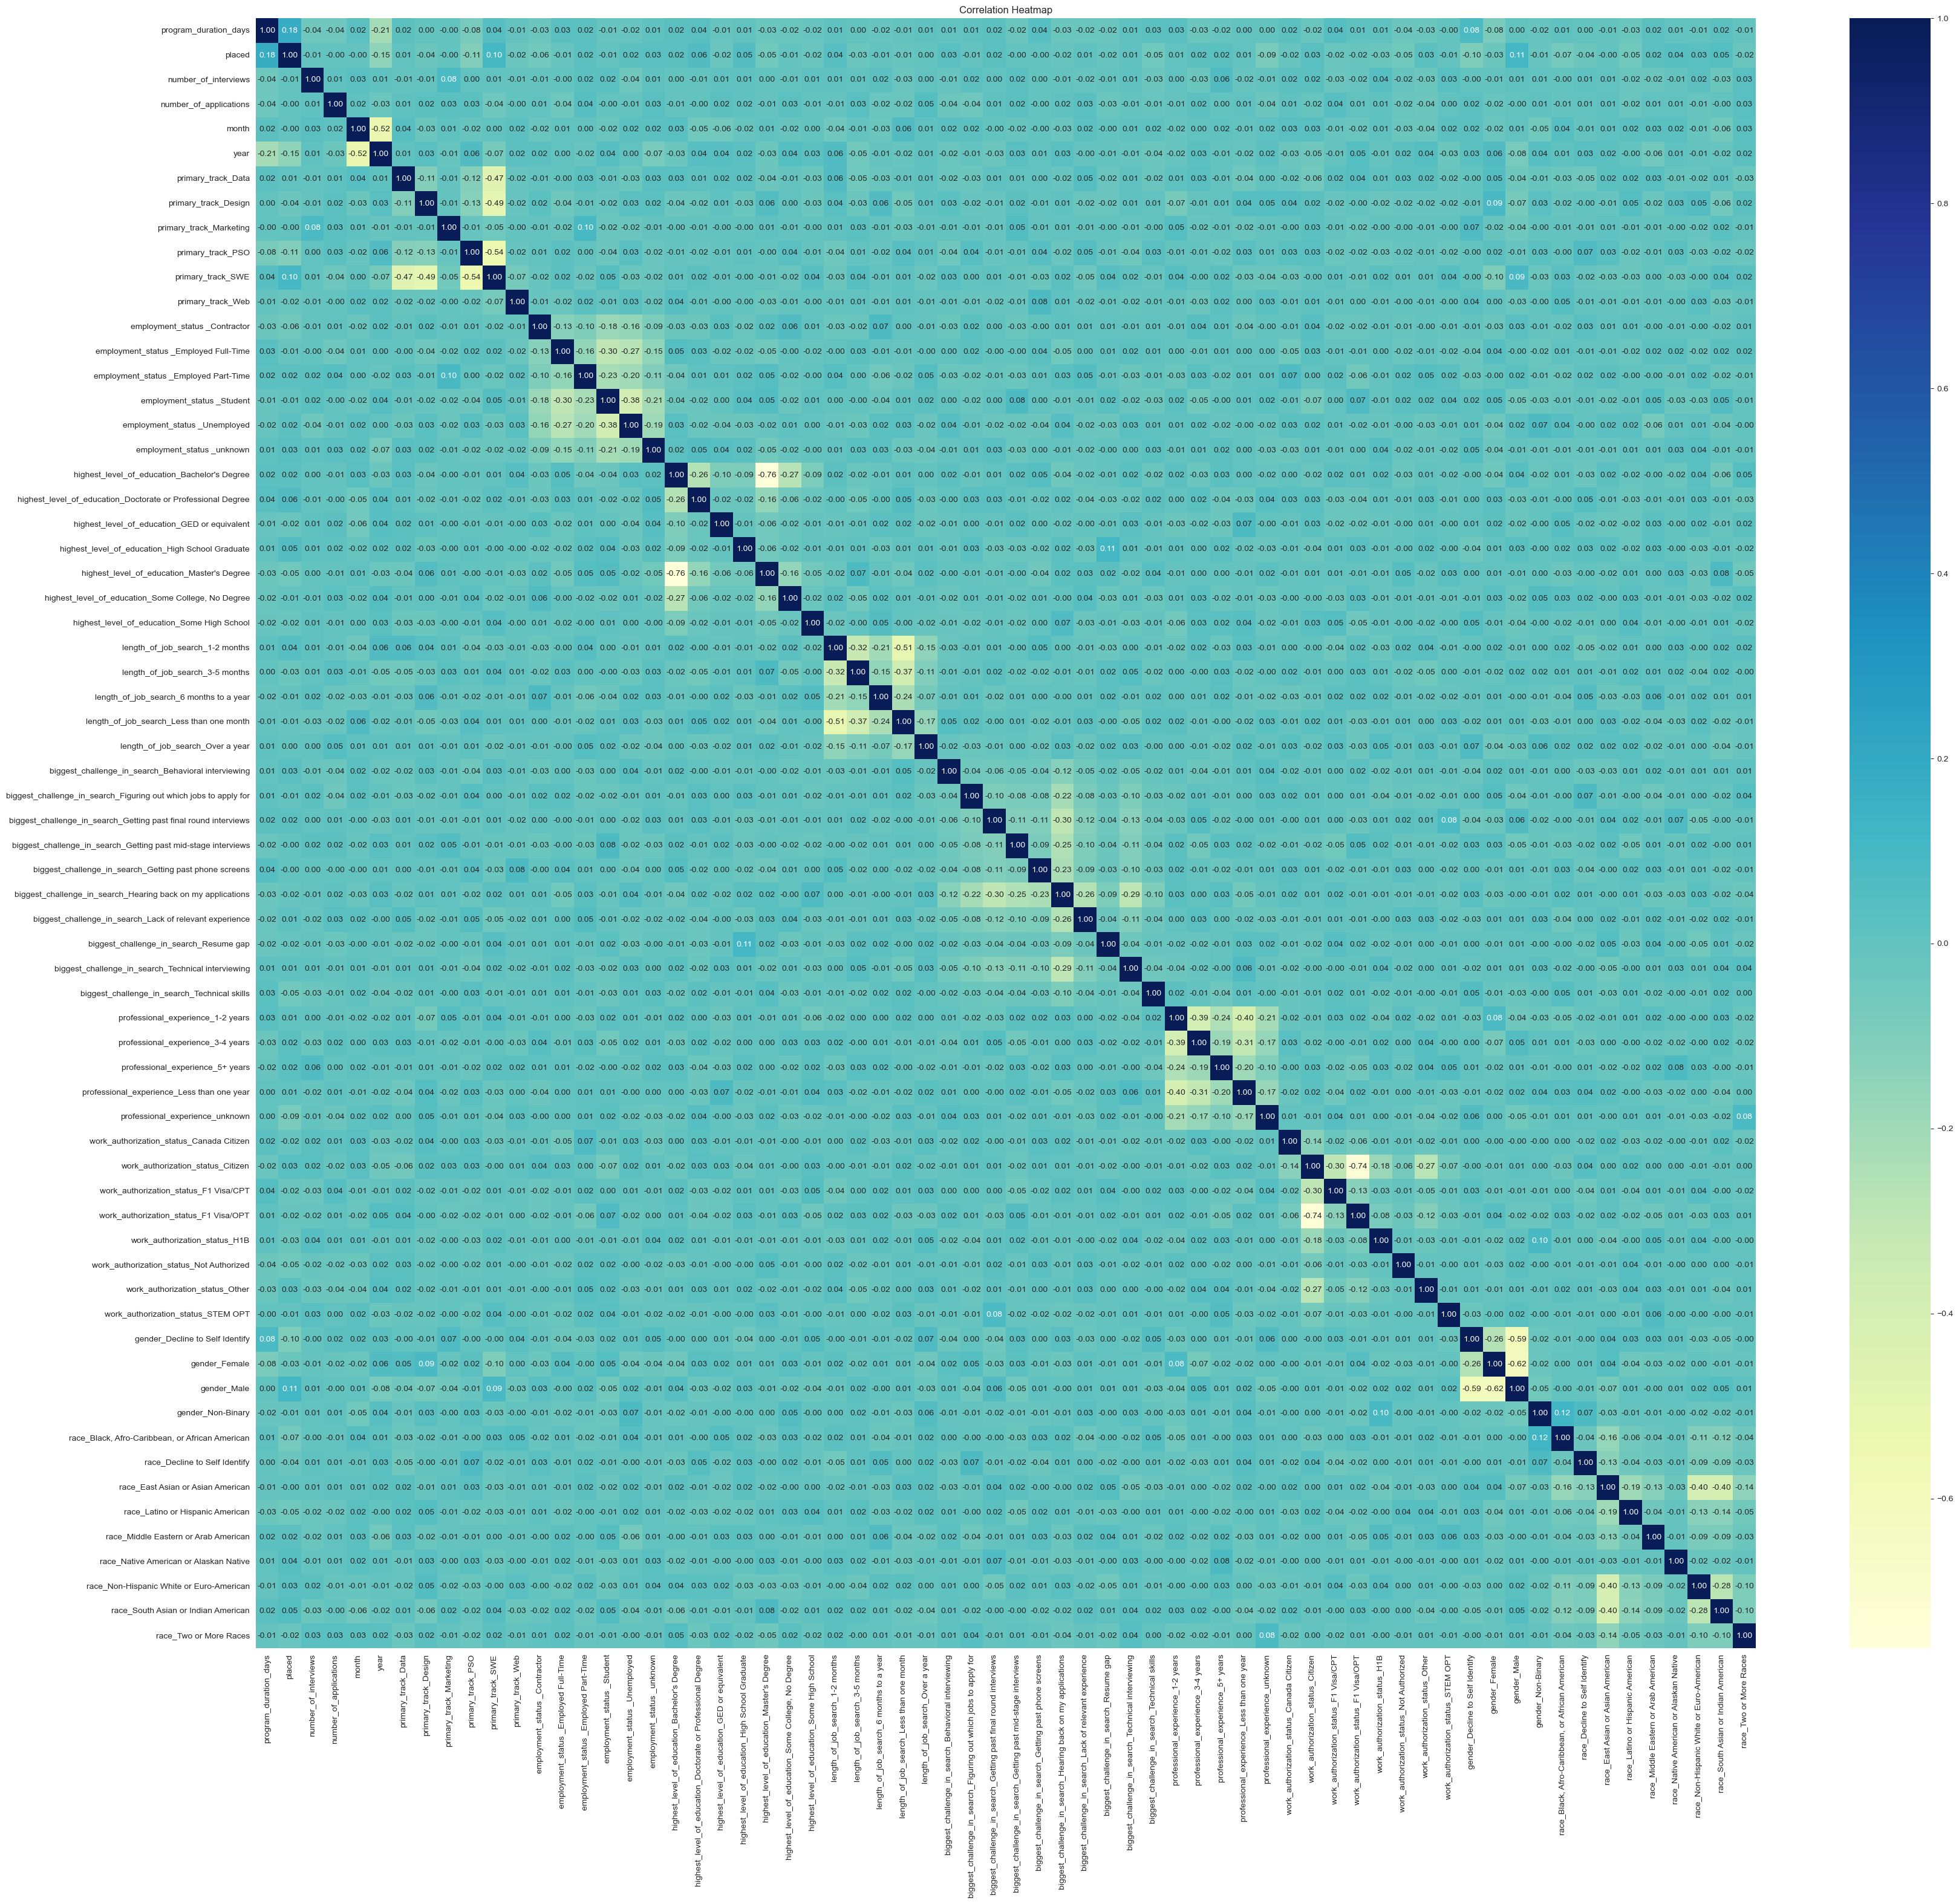

In [62]:
# Set the style of the plot
sns.set_style(style=None, rc=None)

# Create a figure and axis objects
fig, ax = plt.subplots(figsize=(40, 35))

# Compute the correlation matrix for the encoded dataframe
corr_matrix = df.corr()

# Create the heatmap
sns.heatmap(corr_matrix, cmap="YlGnBu", annot=True, fmt=".2f", ax=ax)

# Set the title of the plot
ax.set_title("Correlation Heatmap")

# Display the plot
plt.show()

### Export the Preprocessed Dataset

The encoded feature table is saved as `Pathrise_preprocessed.csv` and then reloaded for modeling. This export provides a reusable handoff between preprocessing and classification.


In [63]:
df.to_csv('Pathrise_preprocessed.csv', index=False)

In [64]:
df = pd.read_csv('Pathrise_preprocessed.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1744 entries, 0 to 1743
Data columns (total 66 columns):
 #   Column                                                            Non-Null Count  Dtype  
---  ------                                                            --------------  -----  
 0   program_duration_days                                             1744 non-null   float64
 1   placed                                                            1744 non-null   int64  
 2   number_of_interviews                                              1744 non-null   float64
 3   number_of_applications                                            1744 non-null   int64  
 4   month                                                             1744 non-null   int64  
 5   year                                                              1744 non-null   int64  
 6   primary_track_Data                                                1744 non-null   bool   
 7   primary_track_Design             

## Phase 7: Machine Learning Modeling & Classification Pipeline

This phase defines the placement target, scales the predictors, partitions the data, and compares five classifiers using cross-validated hyperparameter search. The implementation details and evaluation follow in the subsections below.

### Classification Task and Class Balance

The target is `placed`; the plot below provides a view of its class distribution before the modeling workflow.

<Axes: xlabel='placed', ylabel='count'>

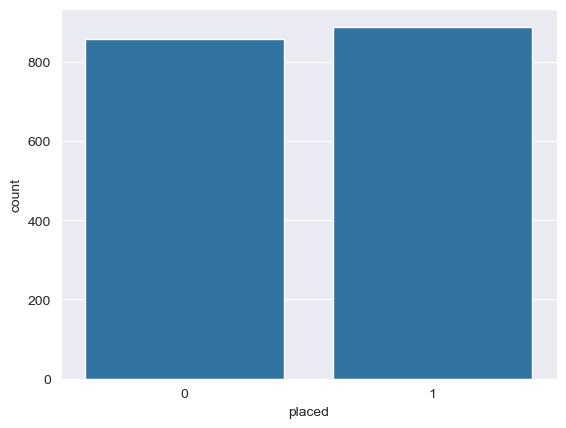

In [65]:
sns.countplot(x='placed',data=df)

### Modeling Tools and Estimators

The following setup imports the scikit-learn estimators, splitting and search utilities, and evaluation metrics used in the classification workflow.


### Import the Modeling Tools

These imports provide the preprocessing, classifiers, cross-validation search, and evaluation tools used below.

In [66]:
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, auc

### Enable Inline Plot Display

This notebook magic asks Jupyter to display Matplotlib figures directly beneath the cell that creates them.

In [67]:
%matplotlib inline

### Separate Predictors from the Outcome

`X` holds the input features and `y` holds the `placed` label to be predicted. Keeping the outcome out of `X` prevents target leakage into model inputs.

In [68]:
X = df.drop("placed", axis=1)
y= df["placed"]

### Standardize Feature Values

Standardization places features on comparable scales, which is especially important for distance- and margin-based models such as KNN and SVM. This notebook fits the scaler before splitting; a production workflow should fit it on training data only to avoid test-set leakage.

In [69]:
# Scaling is applied after the train/test split (see the split cell) to avoid data leakage.

### Restore Feature Names after Scaling

The scaled array is wrapped back into a DataFrame using the original column names so later cells can work with a labeled feature table.

In [70]:
col = X.columns

In [71]:
X

,program_duration_days,number_of_interviews,number_of_applications,month,year,primary_track_Data,primary_track_Design,primary_track_Marketing,primary_track_PSO,primary_track_SWE,...,gender_Non-Binary,"race_Black, Afro-Caribbean, or African American",race_Decline to Self Identify,race_East Asian or Asian American,race_Latino or Hispanic American,race_Middle Eastern or Arab American,race_Native American or Alaskan Native,race_Non-Hispanic White or Euro-American,race_South Asian or Indian American,race_Two or More Races
0,0.0,0.0,0,8,2019,False,True,False,False,False,...,False,False,False,True,False,False,False,False,False,False
1,0.0,5.0,25,8,2019,False,False,False,True,False,...,False,False,True,False,False,False,False,False,False,False
2,0.0,0.0,9,8,2019,False,False,False,False,True,...,False,True,False,False,False,False,False,False,False,False
3,19.0,4.0,15,8,2019,False,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,13.0,0.0,10,9,2019,False,False,False,False,True,...,False,True,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1739,0.0,0.0,20,9,2019,False,False,False,True,False,...,False,False,False,False,False,False,False,False,True,False
1740,118.0,1.0,25,7,2019,False,False,False,False,True,...,False,False,False,False,False,True,False,False,False,False
1741,457.0,4.0,15,6,2018,False,True,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1742,488.0,1.0,7,1,2019,True,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False


### Create a 70/30 Train–Test Split

70% of rows are used for training and 30% are held out for final testing. `random_state=101` makes the random split repeatable; the code does not request stratification.

In [72]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=101)

# Fit the scaler on the training partition only, then apply it to the test partition
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=col)
X_test = pd.DataFrame(scaler.transform(X_test), columns=col)

### Initialize the Candidate Classifiers

Create one estimator for each approach—KNN, SVM, Decision Tree, Random Forest, and Logistic Regression—before tuning their settings.

In [73]:
# Define classifiers
knn = KNeighborsClassifier()
svm = SVC()
dt = DecisionTreeClassifier()
rf = RandomForestClassifier()
lr = LogisticRegression()

### Define Hyperparameter Grids

Each dictionary lists the candidate settings to compare. Grid search evaluates combinations from these grids rather than relying on a single arbitrary configuration.

In [74]:
param_grid_knn = {'n_neighbors': [3, 5, 7, 9]}
param_grid_svm = {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}
param_grid_dt = {'criterion': ['gini', 'entropy'], 'max_depth': [3, 5, 7, 9]}
param_grid_rf = {'n_estimators': [50, 100, 150, 200], 'max_depth': [3, 5, 7, 9]}
param_grid_lr = {'C': [0.1, 1, 10]}

### Configure GridSearchCV and 10-Fold Cross-Validation

`GridSearchCV` tests each parameter combination. With `cv=10`, the training data is divided into ten folds: each fold is held out in turn while the other nine train the model, and the scores are averaged for selection.

In [75]:
grid_knn = GridSearchCV(knn, param_grid_knn, cv=10)
grid_svm = GridSearchCV(svm, param_grid_svm, cv=10)
grid_dt = GridSearchCV(dt, param_grid_dt, cv=10)
grid_rf = GridSearchCV(rf, param_grid_rf, cv=10)
grid_lr = GridSearchCV(lr, param_grid_lr, cv=10)

### Fit the Five Grid Searches

The searches below use only the training partition. Each one evaluates its candidate settings with cross-validation and retains the best-performing configuration.

In [76]:
grid_knn.fit(X_train, y_train)
grid_svm.fit(X_train, y_train)
grid_dt.fit(X_train, y_train)
grid_rf.fit(X_train, y_train)
grid_lr.fit(X_train, y_train)

,estimator,LogisticRegression()
,param_grid,"{'C': [0.1, 1, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,10
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


### Retrieve the Best Hyperparameters

The `best_params_` attribute reports the settings selected by cross-validation for each classifier.

In [77]:
# Print best hyperparameters for each model
print('Best hyperparameters for KNN:', grid_knn.best_params_)
print('Best hyperparameters for SVM:', grid_svm.best_params_)
print('Best hyperparameters for DT:', grid_dt.best_params_)
print('Best hyperparameters for RF:', grid_rf.best_params_)
print('Best hyperparameters for LR:', grid_lr.best_params_)

Best hyperparameters for KNN: {'n_neighbors': 7}
Best hyperparameters for SVM: {'C': 1, 'kernel': 'rbf'}
Best hyperparameters for DT: {'criterion': 'gini', 'max_depth': 3}
Best hyperparameters for RF: {'max_depth': 9, 'n_estimators': 150}
Best hyperparameters for LR: {'C': 1}


### Rebuild Models with the Selected Settings

Initialize fresh estimators using the best values found by each search. These are the final models that will be trained and evaluated.

In [78]:
knn = KNeighborsClassifier(n_neighbors=grid_knn.best_params_['n_neighbors'])
svm = SVC(C=grid_svm.best_params_['C'], kernel=grid_svm.best_params_['kernel'])
dt = DecisionTreeClassifier(criterion=grid_dt.best_params_['criterion'], max_depth=grid_dt.best_params_['max_depth'])
rf = RandomForestClassifier(n_estimators=grid_rf.best_params_['n_estimators'], max_depth=grid_rf.best_params_['max_depth'])
lr = LogisticRegression(C=grid_lr.best_params_['C'])

### Retrain Each Final Classifier

Fit all five selected estimators on the complete training partition. The separate test set remains untouched for the next evaluation stage.

In [79]:
knn.fit(X_train, y_train)
svm.fit(X_train, y_train)
dt.fit(X_train, y_train)
rf.fit(X_train, y_train)
lr.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


## Phase 8: Model Evaluation & Performance Comparison

The fitted classifiers are compared on the held-out test set. The following cells report accuracy, confusion matrices, and classification reports, plot ROC curves with AUC summaries, and serialize each trained classifier with Pickle for later reuse.

### Accuracy and Confusion Matrix

Accuracy is the fraction of test examples classified correctly. A confusion matrix counts correct and incorrect predictions by actual and predicted class, making class-specific errors visible. The classification report below also summarizes precision, recall, and F1-score.

### Test-Set Metrics

For each classifier, predictions on the test partition are summarized with accuracy, a confusion matrix, and a classification report.


In [80]:
import warnings
from sklearn.exceptions import DataConversionWarning

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DataConversionWarning)

## Initializing models, model_names and evaluation metrics
models = [knn, svm, dt, rf, lr]
model_names = ['KNN', 'SVM', 'DT', 'RF', 'LR']
accuracies = []
confusion_matrices = []
fprs = []
tprs = []
aucs = []

## Loop through models to make predictions using each model
for model in models:
    y_pred = model.predict(X_test)
    # Use continuous scores (probabilities or decision values) for ROC/AUC
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test)[:, 1]
    else:
        scores = model.decision_function(X_test)
    ## store evaluation metrics of each model
    accuracies.append(accuracy_score(y_test, y_pred))
    confusion_matrices.append(confusion_matrix(y_test, y_pred))
    fpr, tpr, _ = roc_curve(y_test, scores)
    fprs.append(fpr)
    tprs.append(tpr)
    aucs.append(auc(fpr, tpr))

Model: KNN
Accuracy Score: 0.56


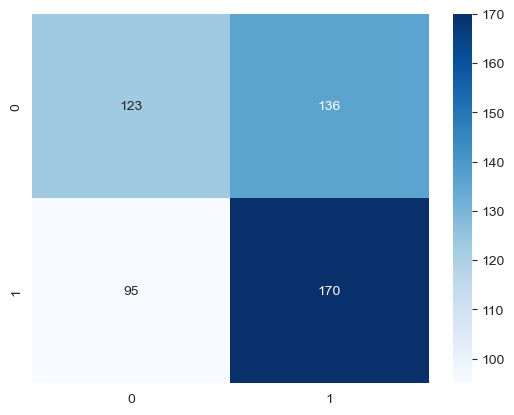

Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.47      0.52       259
           1       0.56      0.64      0.60       265

    accuracy                           0.56       524
   macro avg       0.56      0.56      0.56       524
weighted avg       0.56      0.56      0.56       524
 

Model: SVM
Accuracy Score: 0.62


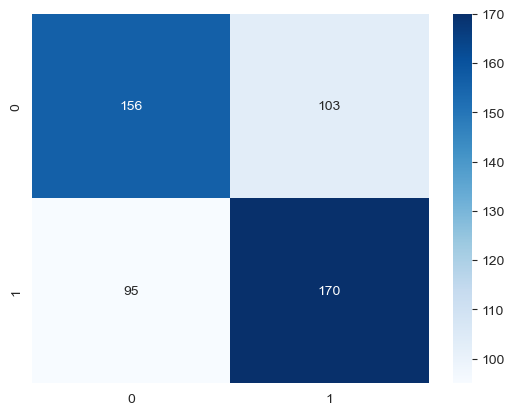

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.60      0.61       259
           1       0.62      0.64      0.63       265

    accuracy                           0.62       524
   macro avg       0.62      0.62      0.62       524
weighted avg       0.62      0.62      0.62       524
 

Model: DT
Accuracy Score: 0.78


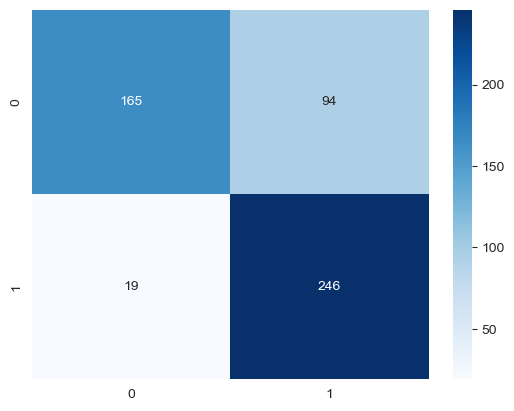

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.64      0.74       259
           1       0.72      0.93      0.81       265

    accuracy                           0.78       524
   macro avg       0.81      0.78      0.78       524
weighted avg       0.81      0.78      0.78       524
 

Model: RF
Accuracy Score: 0.76


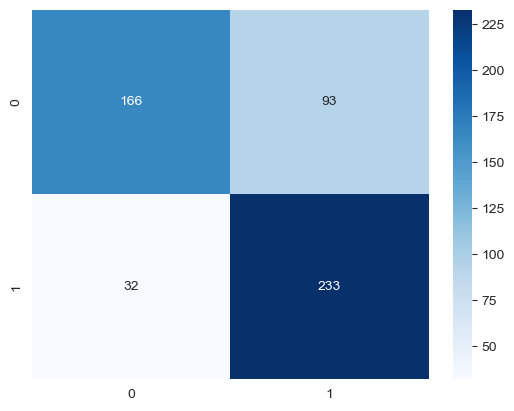

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.64      0.73       259
           1       0.71      0.88      0.79       265

    accuracy                           0.76       524
   macro avg       0.78      0.76      0.76       524
weighted avg       0.78      0.76      0.76       524
 

Model: LR
Accuracy Score: 0.62


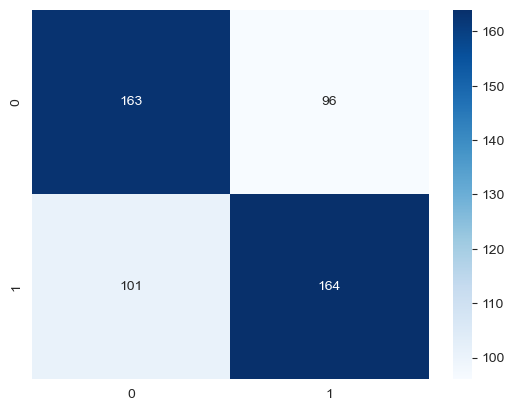

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.63      0.62       259
           1       0.63      0.62      0.62       265

    accuracy                           0.62       524
   macro avg       0.62      0.62      0.62       524
weighted avg       0.62      0.62      0.62       524
 



In [81]:
import seaborn as sns
from sklearn.metrics import classification_report

for i in range(len(models)):
    print(f"Model: {model_names[i]}")
    print(f"Accuracy Score: {accuracies[i]:.2f}")
    sns.heatmap(confusion_matrices[i], annot=True, cmap="Blues", fmt='d')
    plt.show()
    y_pred = models[i].predict(X_test)
    print("Classification Report:")
    print(classification_report(y_test, y_pred), "\n")

### Understand ROC-AUC

The ROC curve traces the true-positive rate against the false-positive rate. AUC summarizes that curve: higher values indicate better separation. The ROC analysis below uses predicted probabilities (or decision-function values for SVM), which is the conventional approach; hard class labels would only give a coarse summary.

### ROC Curves and AUC

The ROC plot compares true-positive and false-positive rates across the five classifiers. AUC values are calculated from predicted probabilities (`predict_proba`) or decision-function scores for SVM.

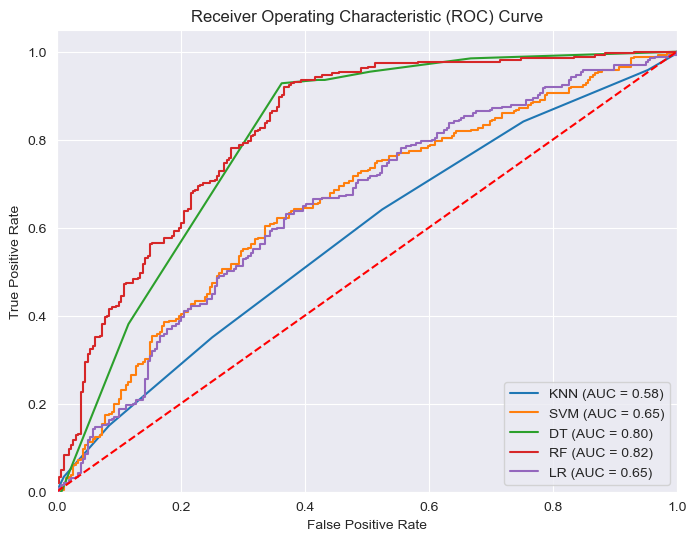

In [82]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
for i in range(len(models)):
    plt.plot(fprs[i], tprs[i], label=model_names[i] + " (AUC = {:.2f})".format(aucs[i]))
plt.plot([0, 1], [0, 1], 'r--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()


### Save the Trained Models

Pickle serialization stores each fitted classifier in a file so it can be loaded later without repeating training. Only unpickle files from trusted sources.

### Model Serialization

The final fitted classifiers are saved as separate Pickle files. Pickle artifacts should only be loaded from trusted sources and are most reliable when used with compatible Python and scikit-learn versions.


In [83]:
import pickle

In [84]:
pickle.dump(knn,open('pathrise-knn.pkl','wb'))
pickle.dump(svm,open('pathrise-svm.pkl','wb'))
pickle.dump(dt,open('pathrise-dt.pkl','wb'))
pickle.dump(rf,open('pathrise-rf.pkl','wb'))
pickle.dump(lr,open('pathrise-lr.pkl','wb'))

## Phase 9: Baseline / Supplementary Regression Analysis

As a supplementary analysis, a linear regression estimator is fit to the same features and train/test partitions to predict the binary placement outcome as a numeric response. Mean Absolute Error (MAE) and Mean Squared Error (MSE) are reported. Because placement is a classification target, this regression is a baseline exercise rather than the primary modeling approach.

### Linear Regression Baseline

The following cell fits the linear model, generates predictions for the test set, and calculates MAE and MSE.

In [85]:
from sklearn.linear_model import LinearRegression


lm = LinearRegression()


lm.fit(X_train,y_train)

LinearRegression()

predictions = lm.predict(X_test)


from sklearn import metrics


print('MAE:', metrics.mean_absolute_error(y_test, predictions))
print('MSE:', metrics.mean_squared_error(y_test, predictions))



MAE: 0.4562764706641304
MSE: 0.23877183341782032
